#### **Import models**

In [1]:
import pandas as pd
import matplotlib.pyplot  as plt
import numpy as np
import seaborn as sns
import sklearn as sk

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multioutput import MultiOutputClassifier


from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    multilabel_confusion_matrix,
    precision_recall_curve,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

import warnings
warnings.filterwarnings('ignore')



#### **Load and Inspect Data**

In [2]:
df = pd.read_csv('ai4i2020.csv')
display(df.head())
display(df.tail())
df.shape

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


(10000, 14)

In [3]:
print("Missing values per column:\n")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nUnique values per column:")
print(df.nunique())

Missing values per column:

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate rows: 0

Unique values per column:
UDI                        10000
Product ID                 10000
Type                           3
Air temperature [K]           93
Process temperature [K]       82
Rotational speed [rpm]       941
Torque [Nm]                  577
Tool wear [min]              246
Machine failure                2
TWF                            2
HDF                            2
PWF                            2
OSF                            2
RNF                            2
dtype: int64


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0


In [5]:
df.columns.tolist()

['UDI',
 'Product ID',
 'Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Machine failure',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

#### **Exploratory Data Analysis**

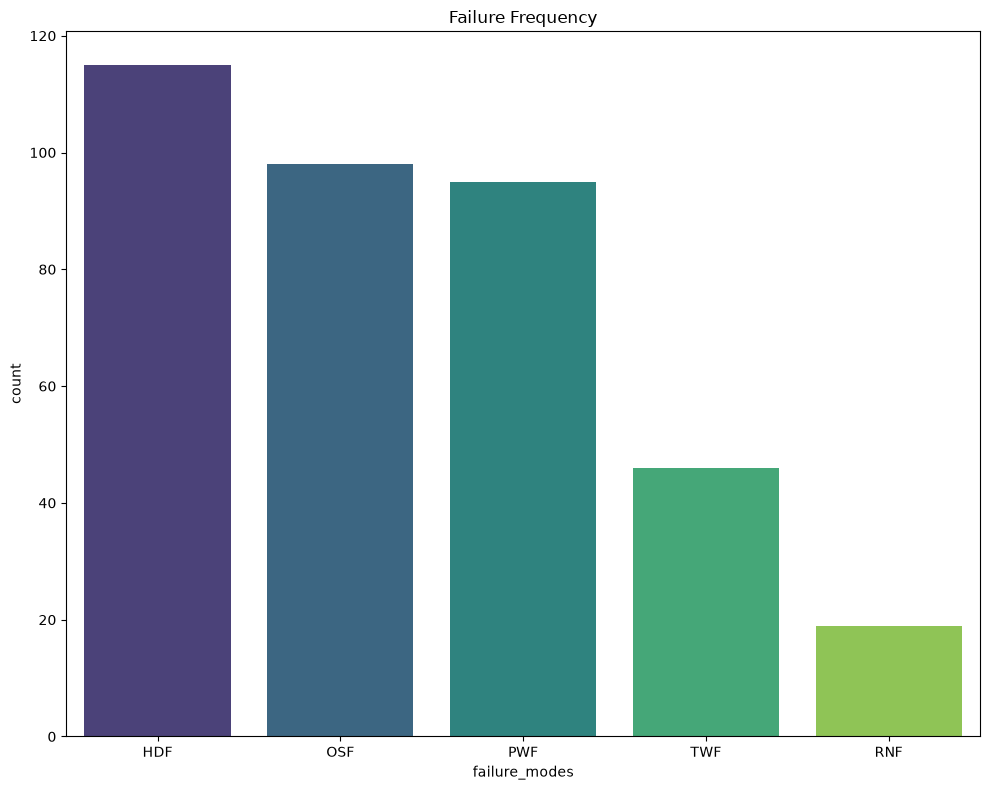

In [6]:
failure_modes =[
'TWF','HDF','PWF','OSF','RNF'
]

failure_sum = df[failure_modes].sum().sort_values(ascending = False)
plt.figure(figsize= (10,8))
sns.barplot(x = failure_sum.index,y = failure_sum.values,palette ='viridis')
plt.title('Failure Frequency')
plt.xlabel('failure_modes')
plt.ylabel('count')
plt.tight_layout()
plt.show()

*   **Correlation Heatmap**

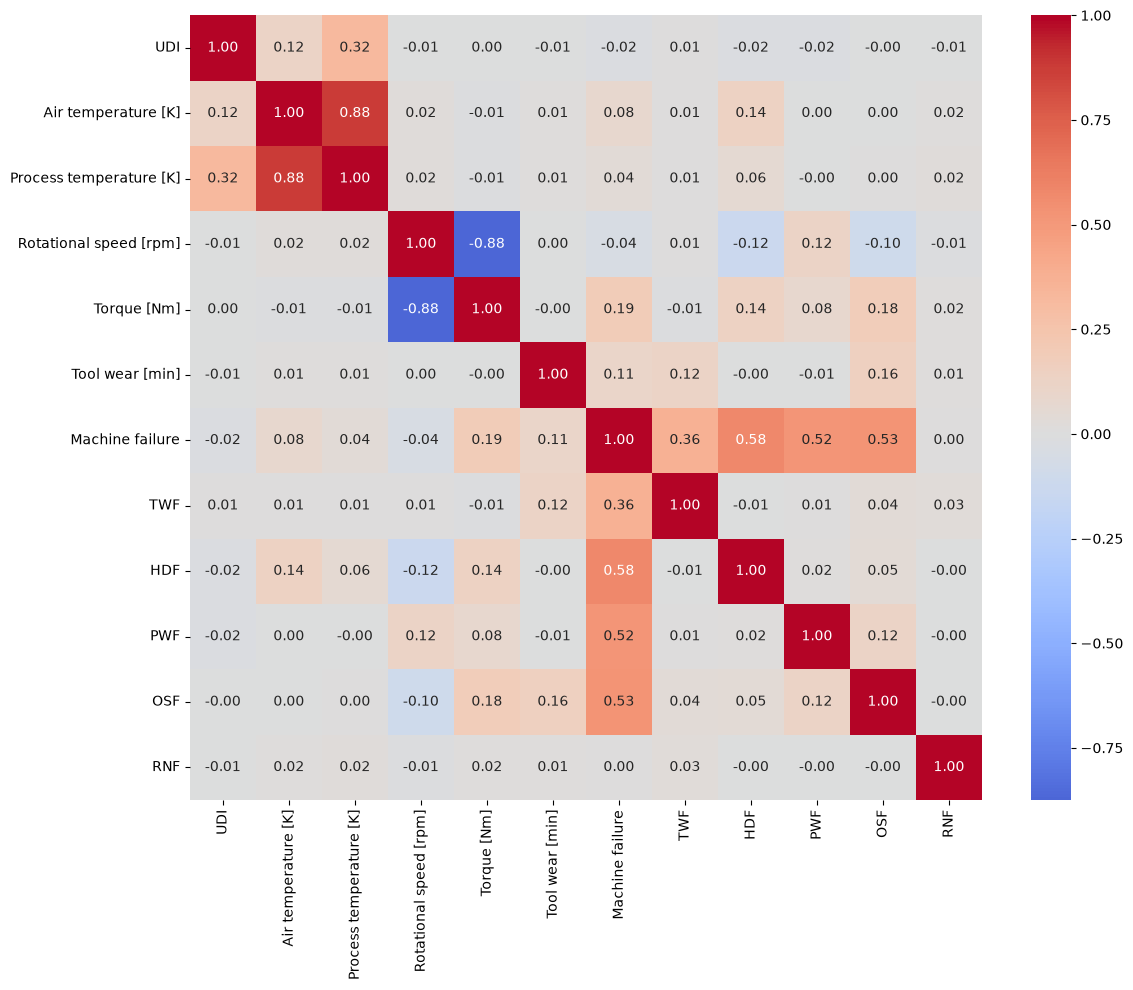

In [7]:
cols = df.select_dtypes(include=['int64','float64']).columns

plt.figure(figsize = (12,10))
sns.heatmap(
    df[cols].corr(),
    annot=True,
    fmt ='.2f',
    cmap='coolwarm',
    center = 0,
    )

plt.tight_layout()
plt.show()


#### **Feature Engineering**

*   **Check For Class Imbablance**

In [8]:
for i in failure_modes:
    print(df[i].value_counts(normalize=True)*100)


TWF
0    99.54
1     0.46
Name: proportion, dtype: float64
HDF
0    98.85
1     1.15
Name: proportion, dtype: float64
PWF
0    99.05
1     0.95
Name: proportion, dtype: float64
OSF
0    99.02
1     0.98
Name: proportion, dtype: float64
RNF
0    99.81
1     0.19
Name: proportion, dtype: float64


The engineered features reflect plausible physical failure mechanisms:

- `Temp_diff`: temperature difference between process and ambient air, relevant to heat dissipation.
- `Power`: torque multiplied by angular velocity, relevant to power failure.
- `Overstrain`: torque multiplied by accumulated tool wear, relevant to overstrain failure.


In [9]:
new_df = df.copy()

#creating new features

new_df["Temp_diff [K]"] = (
    new_df["Process temperature [K]"] - new_df["Air temperature [K]"]
)

new_df['Overstrain [Nm*min]'] =(
    new_df['Torque [Nm]'] * new_df['Tool wear [min]']
)

new_df['Power [W]'] = (
    new_df['Torque [Nm]'] * new_df['Rotational speed [rpm]'] * 2* np.pi/60
)

In [10]:
new_df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Temp_diff [K],Overstrain [Nm*min],Power [W]
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,10.5,0.0,6951.590560
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,10.5,138.9,6826.722724
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,10.4,247.0,7749.387543
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,10.4,276.5,5927.504659
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,10.5,360.0,5897.816608


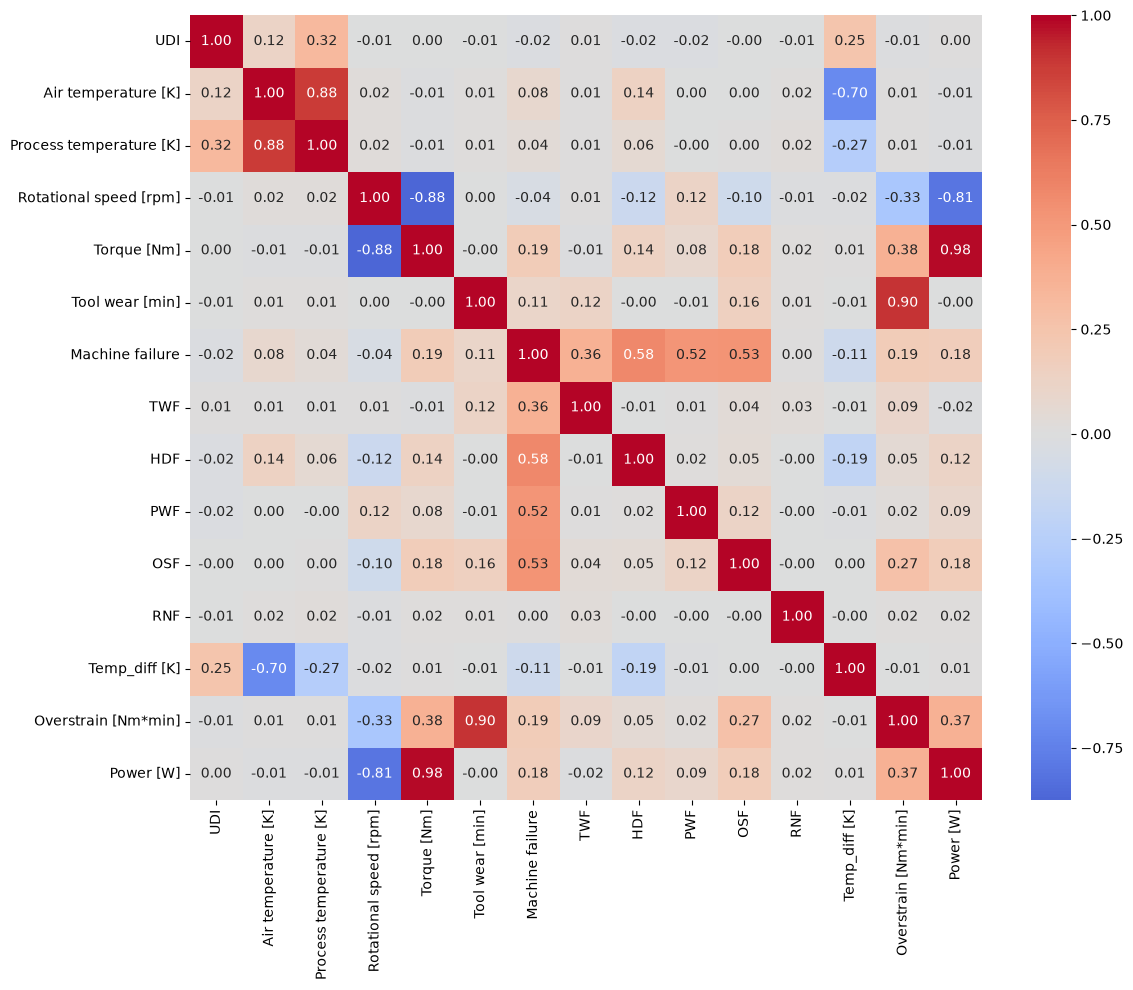

In [11]:
cols = new_df.select_dtypes(include=['int64','float64']).columns

plt.figure(figsize = (12,10))
sns.heatmap(
    new_df[cols].corr(),
    annot=True,
    fmt ='.2f',
    cmap='coolwarm',
    center = 0,
    )

plt.tight_layout()
plt.show()


*   **Feature selection**

In [12]:
X = new_df[[
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temp_diff [K]",
    "Power [W]",
    "Overstrain [Nm*min]"
]]

#encode categorical columns 
X =pd.get_dummies(X,columns=['Type'],drop_first=True,dtype=int)


`RNF` is excluded from the supervised targets because it is random and not explained by the sensor readings.

In [13]:
target_modes = ['TWF', 'HDF', 'PWF', 'OSF']
y = new_df[target_modes]

In [14]:
y.columns.tolist()

['TWF', 'HDF', 'PWF', 'OSF']

### Train Data

In [15]:
msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

for train_idx, test_idx in msss.split(X, y):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(X_test.shape)
print(X_train.shape)
print(y_train.shape)
print(y_test.shape)

(2000, 10)
(8000, 10)
(8000, 4)
(2000, 4)


*    **Scale Data**

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(8000, 10)
(2000, 10)


In [17]:
models = {
    "Logistic Regression": MultiOutputClassifier(
        LogisticRegression(
            random_state=42,
            max_iter=1000,
            class_weight="balanced",
        )
    ),
    "XGBoost": MultiOutputClassifier(
        XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=3,
            reg_alpha=0.1,
            reg_lambda=1.0,
            scale_pos_weight=20,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1,
        )
    ),
    "LightGBM": MultiOutputClassifier(
        LGBMClassifier(
            n_estimators=200,
            max_depth=5,
            num_leaves=15,
            learning_rate=0.05,
            random_state=42,
            verbosity=-1,
            n_jobs=-1,
        )
    ),
    
}


                                                                                                                                                                         

In [18]:
from sklearn.metrics import f1_score, hamming_loss, average_precision_score

results = {}

for name, model in models.items():
    print(f"{name} Model")

    model.fit(X_train_scaled,y_train)

    predictions = model.predict(X_test_scaled)

    # Extract probabilities for PR-AUC (crucial for imbalanced data)

    y_prob = np.column_stack([
        est.predict_proba(X_test_scaled)[:, 1] for est in model.estimators_
    ])

    #store predictions
    results[name] = {"predictions":predictions,"probabilities":y_prob}

    print(classification_report(y_test,predictions,target_names=target_modes))

    #evaluation metrics
    macro_f1 = f1_score(y_test, predictions,average='macro', zero_division=0)
    pre_score = average_precision_score(y_test,predictions,average='macro')
    ham_loss = hamming_loss(y_test,predictions)

    #print result Macro PR-AUC
    print(f"Macro F1-Score: {macro_f1:.2f} | Macro PR-Auc: {pre_score:.2f} | Hamming Loss: {ham_loss:.4f}\n")


Logistic Regression Model


              precision    recall  f1-score   support

         TWF       0.05      1.00      0.10         9
         HDF       0.29      1.00      0.45        23
         PWF       0.38      0.95      0.54        19
         OSF       0.62      1.00      0.77        20

   micro avg       0.21      0.99      0.35        71
   macro avg       0.34      0.99      0.46        71
weighted avg       0.38      0.99      0.52        71
 samples avg       0.03      0.03      0.03        71

Macro F1-Score: 0.46 | Macro PR-Auc: 0.33 | Hamming Loss: 0.0326

XGBoost Model
              precision    recall  f1-score   support

         TWF       0.00      0.00      0.00         9
         HDF       0.92      1.00      0.96        23
         PWF       0.76      1.00      0.86        19
         OSF       0.90      0.95      0.93        20

   micro avg       0.75      0.86      0.80        71
   macro avg       0.65      0.74      0.69        71
weighted avg       0.76      0.86      0.80        

### Model Evaluation and Tuning

In [19]:
best_model ='LightGBM'
best_predictions = results[best_model]['predictions']
best_prob = results[best_model]['probabilities']



*   **Multilabel confusion matrix**

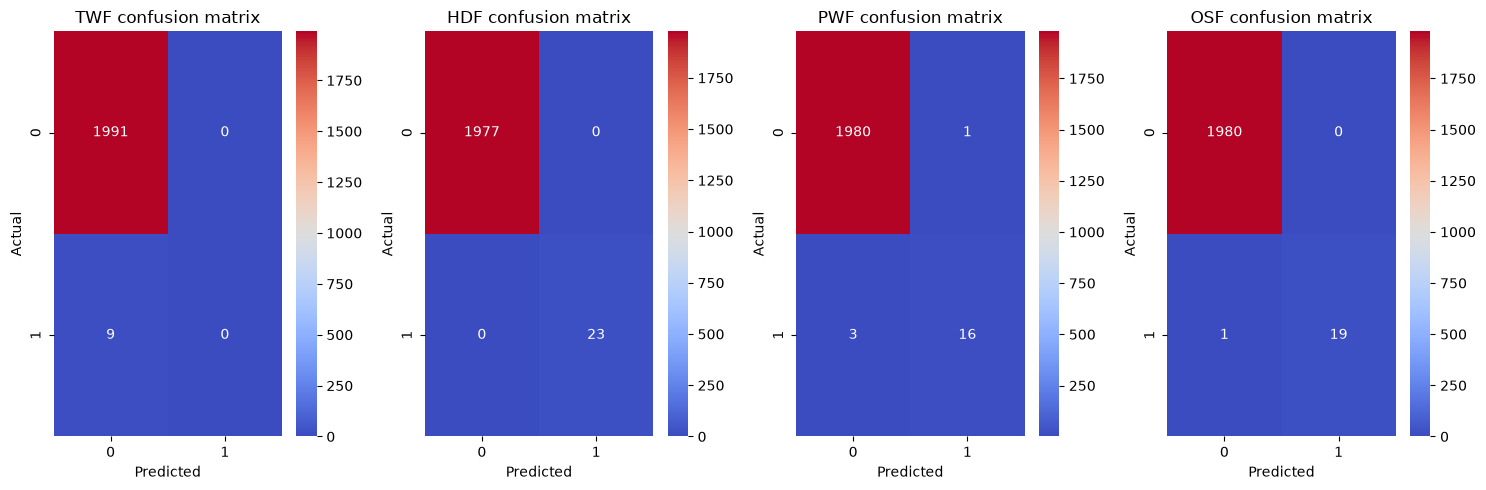

In [20]:
mcm = multilabel_confusion_matrix(y_test, best_predictions)

fig, axes = plt.subplots(1,4, figsize =(15,5))
for i, mode in enumerate(target_modes):
    sns.heatmap(
        mcm[i],
        annot = True,
        fmt ='d',
        cmap ='coolwarm',
        ax = axes[i]
        )
    axes[i].set_title(f'{mode} confusion matrix')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')
plt.tight_layout()
plt.show()


In [21]:
from sklearn.metrics import accuracy_score

#  FDR = FP / (FP + TP) = 1 - Precision
def report_fdr(y_true, y_pred):
    mcm = multilabel_confusion_matrix(y_true, y_pred)
    for i, mode in enumerate(target_modes):
        tn, fp, fn, tp = mcm[i].ravel()
        fdr = fp / (fp + tp) if (fp + tp) > 0 else 0.0
        print(f"{mode}: FDR = {fdr:.2%} (False Positives = {fp}, True Positives = {tp})")
    print(f"Exact-Match Accuracy: {accuracy_score(y_true, y_pred):.4f}\n")

# 1. Default threshold (0.50)
report_fdr(y_test, best_predictions)

# 2. Cost-sensitive threshold tuning (raising threshold to 0.70 to minimize false alarms)
tuned_preds = (best_prob >= 0.70).astype(int)
report_fdr(y_test, tuned_preds)


TWF: FDR = 0.00% (False Positives = 0, True Positives = 0)
HDF: FDR = 0.00% (False Positives = 0, True Positives = 23)
PWF: FDR = 5.88% (False Positives = 1, True Positives = 16)
OSF: FDR = 0.00% (False Positives = 0, True Positives = 19)
Exact-Match Accuracy: 0.9930

TWF: FDR = 0.00% (False Positives = 0, True Positives = 0)
HDF: FDR = 0.00% (False Positives = 0, True Positives = 23)
PWF: FDR = 7.14% (False Positives = 1, True Positives = 13)
OSF: FDR = 0.00% (False Positives = 0, True Positives = 18)
Exact-Match Accuracy: 0.9910

